Изучаем данные из датасета

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Настройки для графиков
%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

#Загружаем данные
data = pd.read_csv('Electric_Vehicle_Population_Data.csv')

print("\nРазмер: ", data.shape)
print("Колонки")
print(data.columns.tolist())


Размер:  (112634, 17)
Колонки
['VIN (1-10)', 'County', 'City', 'State', 'Postal Code', 'Model Year', 'Make', 'Model', 'Electric Vehicle Type', 'Clean Alternative Fuel Vehicle (CAFV) Eligibility', 'Electric Range', 'Base MSRP', 'Legislative District', 'DOL Vehicle ID', 'Vehicle Location', 'Electric Utility', '2020 Census Tract']


In [152]:
#Первые 5 строк
print("Первые пять строк: ")
print(data.head())
print("Информация: ")
data.info()
print("Пропуски в датасете: ")
print(data.isnull().sum())
print(f"\nВсего пропусков: {data.isnull().sum().sum()}")

#Статистика по числовым значениям
print("\nСтатистика по числовым значениям: ")
display(data.describe())

#Уникальные значения в категориях
for stroki_unique in data.select_dtypes(include='str').columns:
    print(f"\n{stroki_unique} ({data[stroki_unique].nunique()} уникальных):")

Первые пять строк: 
   VIN (1-10)     County      City State  Postal Code  Model Year       Make  \
0  JTMEB3FV6N     Monroe  Key West    FL        33040        2022     TOYOTA   
1  1G1RD6E45D      Clark  Laughlin    NV        89029        2013  CHEVROLET   
2  JN1AZ0CP8B     Yakima    Yakima    WA        98901        2011     NISSAN   
3  1G1FW6S08H     Skagit  Concrete    WA        98237        2017  CHEVROLET   
4  3FA6P0SU1K  Snohomish   Everett    WA        98201        2019       FORD   

        Model                   Electric Vehicle Type  \
0  RAV4 PRIME  Plug-in Hybrid Electric Vehicle (PHEV)   
1        VOLT  Plug-in Hybrid Electric Vehicle (PHEV)   
2        LEAF          Battery Electric Vehicle (BEV)   
3     BOLT EV          Battery Electric Vehicle (BEV)   
4      FUSION  Plug-in Hybrid Electric Vehicle (PHEV)   

  Clean Alternative Fuel Vehicle (CAFV) Eligibility  Electric Range  \
0           Clean Alternative Fuel Vehicle Eligible              42   
1           Cl

,Postal Code,Model Year,Electric Range,Base MSRP,Legislative District,DOL Vehicle ID,2020 Census Tract
count,112634.000000,112634.000000,112634.000000,112634.000000,112348.000000,1.126340e+05,1.126340e+05
mean,98156.226850,2019.003365,87.812987,1793.439681,29.805604,1.994567e+08,5.296650e+10
std,2648.733064,2.892364,102.334216,10783.753486,14.700545,9.398427e+07,1.699104e+09
min,1730.000000,1997.000000,0.000000,0.000000,1.000000,4.777000e+03,1.101001e+09
25%,98052.000000,2017.000000,0.000000,0.000000,18.000000,1.484142e+08,5.303301e+10
50%,98119.000000,2020.000000,32.000000,0.000000,34.000000,1.923896e+08,5.303303e+10
75%,98370.000000,2022.000000,208.000000,0.000000,43.000000,2.191899e+08,5.305307e+10
max,99701.000000,2023.000000,337.000000,845000.000000,49.000000,4.792548e+08,5.603300e+10



VIN (1-10) (7548 уникальных):

County (165 уникальных):

City (629 уникальных):

State (45 уникальных):

Make (34 уникальных):

Model (114 уникальных):

Electric Vehicle Type (2 уникальных):

Clean Alternative Fuel Vehicle (CAFV) Eligibility (3 уникальных):

Vehicle Location (758 уникальных):

Electric Utility (73 уникальных):


Визуализация значимых признаков

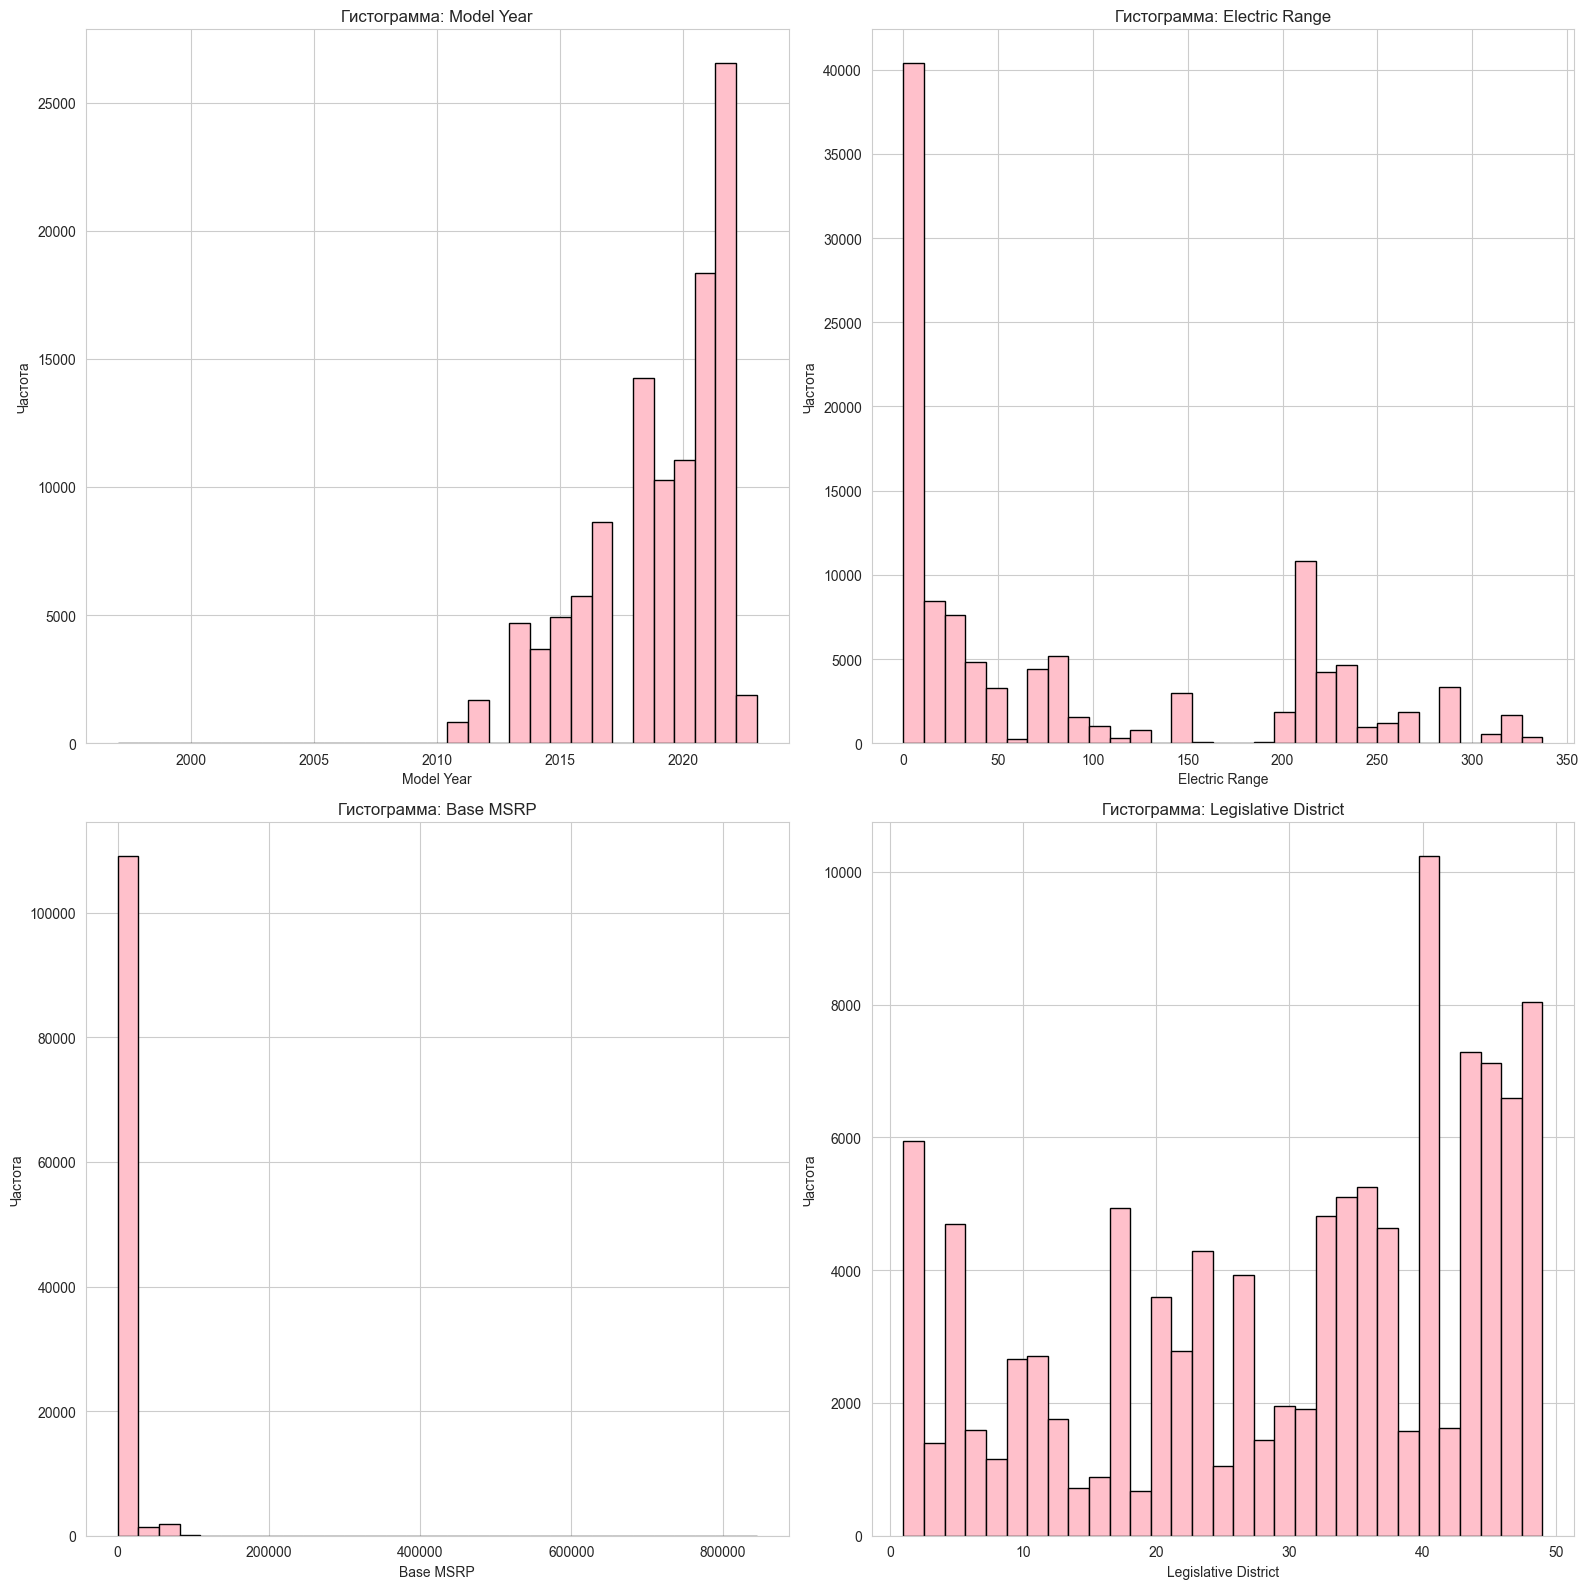

In [153]:
#Гистограммы для числовых колонок
numeric_cols = ['Model Year', 'Electric Range', 'Base MSRP', 'Legislative District']

fig, axes = plt.subplots(2, 2, figsize=(16, 16))
# flatten - превращает двумерный массив в одномерный
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(data[col].dropna(), bins=31, edgecolor='black', color='pink')
    axes[i].set_title(f'Гистограмма: {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Частота')

plt.tight_layout()
plt.show()

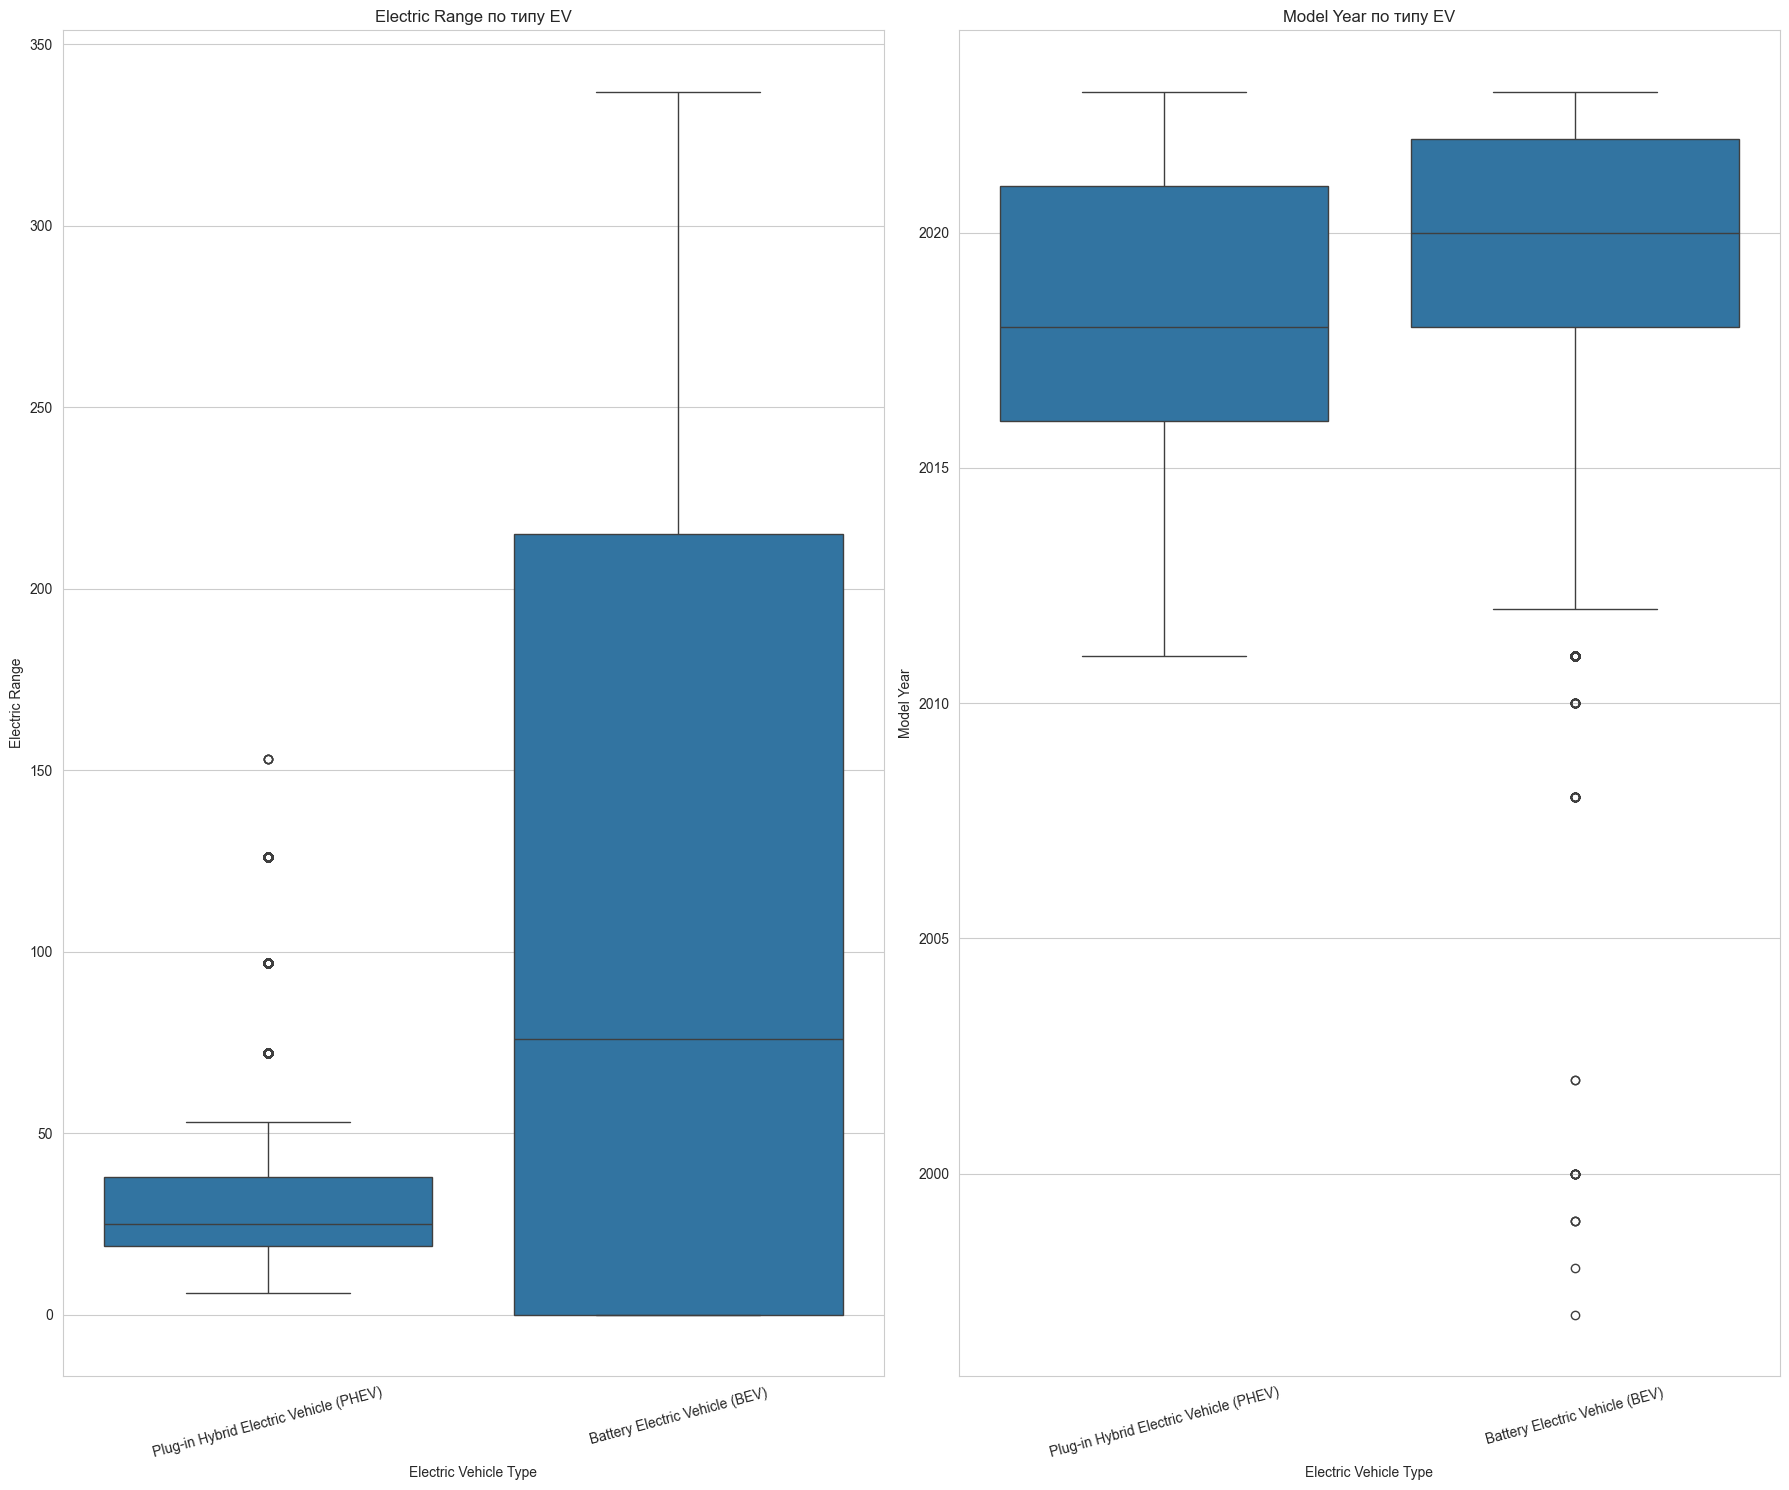

In [154]:
#Построим ящик с усами по эл. диапазону и типу автомобиля
fig, axes = plt.subplots(1, 2, figsize=(18, 15))

sns.boxplot(data=data, x='Electric Vehicle Type', y='Electric Range', ax=axes[0])
axes[0].set_title('Electric Range по типу EV')
axes[0].tick_params(axis='x', rotation=15)

sns.boxplot(data=data, x='Electric Vehicle Type', y='Model Year', ax=axes[1])
axes[1].set_title('Model Year по типу EV')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

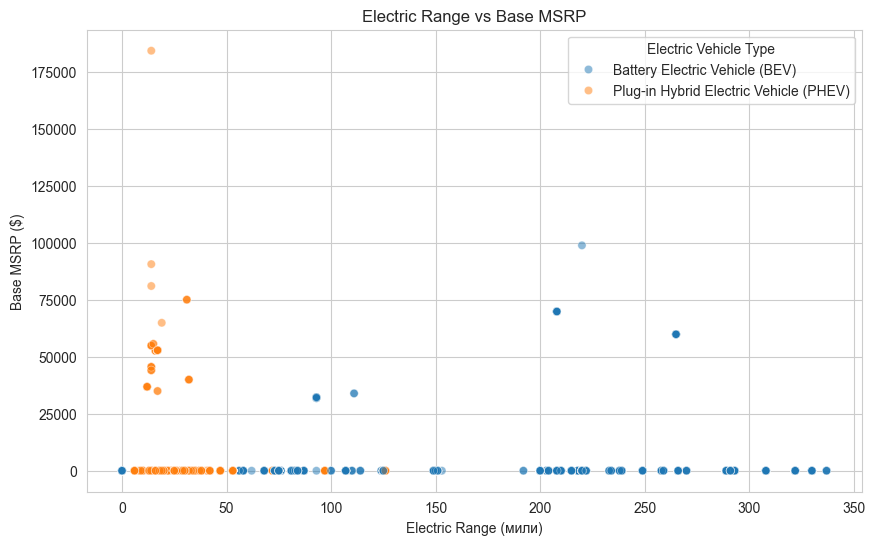

Base MSRP = 0: 109122
Base MSRP > 0: 3512
Base MSRP = 0, %: 96.88193618268018


In [155]:
#Построим диаграмму рассеяния
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=data.sample(5000, random_state=42),
    x='Electric Range', y='Base MSRP',
    hue='Electric Vehicle Type',
    alpha=0.5
)

plt.title('Electric Range vs Base MSRP')
plt.xlabel('Electric Range (мили)')
plt.ylabel('Base MSRP ($)')
plt.show()

#Много значений на нуле так-как в датасете там нули соотетственно
print("Base MSRP = 0:", (data['Base MSRP'] == 0).sum())
print("Base MSRP > 0:", (data['Base MSRP'] > 0).sum())
print("Base MSRP = 0, %:", (data['Base MSRP'] == 0).mean() * 100)

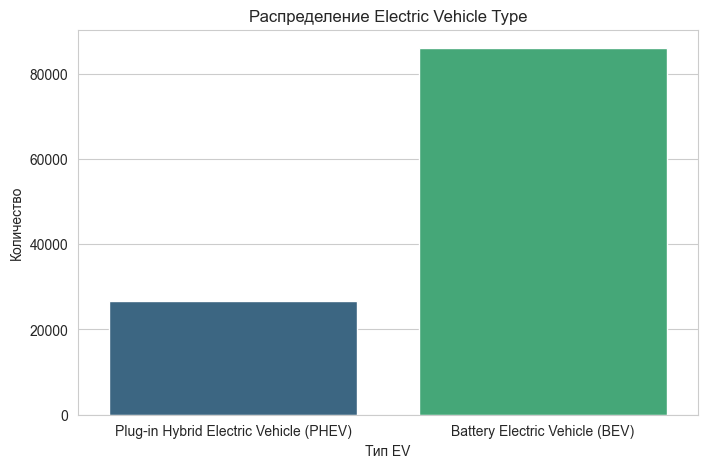

In [156]:
#Распределение целевой переменной
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x='Electric Vehicle Type', hue='Electric Vehicle Type', palette='viridis', legend=False)
plt.title('Распределение Electric Vehicle Type')
plt.xlabel('Тип EV')
plt.ylabel('Количество')
plt.show()

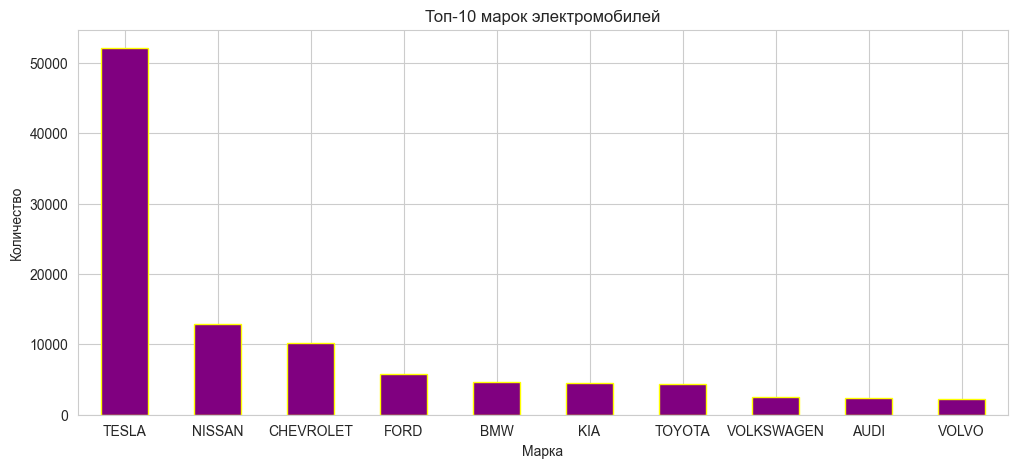

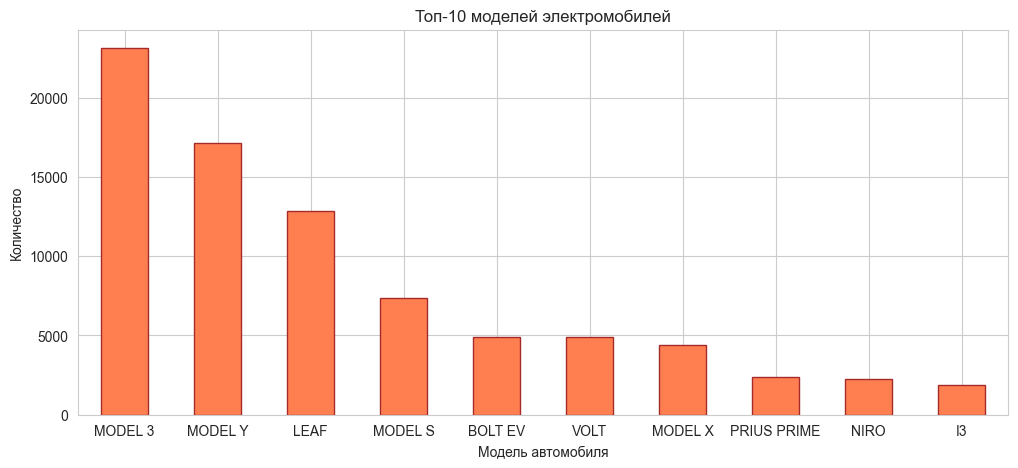

In [157]:
# Топ-10 марок и моделей
plt.figure(figsize=(12, 5))
data['Make'].value_counts().head(10).plot(kind='bar', color='purple', 
                                          edgecolor='yellow')
plt.title('Топ-10 марок электромобилей')
plt.xlabel('Марка')
plt.ylabel('Количество')
plt.xticks(rotation=360)

plt.figure(figsize=(12, 5))
data['Model'].value_counts().head(10).plot(kind='bar', color='coral',
                                            edgecolor='brown')
plt.title('Топ-10 моделей электромобилей')
plt.xlabel('Модель автомобиля')
plt.ylabel('Количество')
plt.xticks(rotation=360)
plt.show()

Очистка данных

In [ ]:
# Второй этап - отчистка данных
# Удаление лишних колонок
columns_to_drops = [
    'VIN (1-10)', #индефикатор - не несёт полезной информации
    'DOL Vehicle ID', #индефикатор тож самое
    'Vehicle Location', #Координаты машины - не зачем, бесполезная инфа
    '2020 Census Tract', #номер района - так же бесполезно
    'Base MSRP', #рекомендованная цена производителя - 99% нулей
    'State', #штат где почти всё WA - тоже не несёт смысловой нагрузки
    'Electric Range',         #утечка данных, те будет предсказание на 99%
    'Model',                  #много уникальных
    'City',                 #много уникальных
    'Electric Utility',  #много уникальных, плохо работает с KNN
    'Clean Alternative Fuel Vehicle (CAFV) Eligibility' #утечка данных
]

data_clean = data.drop(columns=columns_to_drops)

print("Было колонок: ", data.shape[1])
print("Стало колонок: ", data_clean.shape[1])
print('\n', data_clean.columns.tolist())


Было колонок:  17
Стало колонок:  6

 ['County', 'Postal Code', 'Model Year', 'Make', 'Electric Vehicle Type', 'Legislative District']


In [ ]:
# Удаление пропусков
print("Пропуски до:")
print(data_clean.isnull().sum().sum(), "\n")
print(data_clean.isnull().sum(), "\n")

data_clean = data_clean.dropna()

print("Пропуски после: ")
print(data_clean.isnull().sum().sum())
print(data_clean.isnull().sum())
print("Строк осталось:", len(data_clean))

Пропуски до:
286 

County                     0
Postal Code                0
Model Year                 0
Make                       0
Electric Vehicle Type      0
Legislative District     286
dtype: int64 

Пропуски после: 
0
County                   0
Postal Code              0
Model Year               0
Make                     0
Electric Vehicle Type    0
Legislative District     0
dtype: int64
Строк осталось: 112348


In [160]:
# Удаление дубликатов
print("Строк до: ", len(data_clean))

data_clean = data_clean.drop_duplicates()

print("Строк после: ", len(data_clean))
print("Удалено дубликатов: ", len(data) - len(data_clean))

Строк до:  112348
Строк после:  31175
Удалено дубликатов:  81459


Корреляция данных

                      Postal Code  Model Year  Legislative District
Postal Code              1.000000   -0.015249             -0.500178
Model Year              -0.015249    1.000000              0.000589
Legislative District    -0.500178    0.000589              1.000000


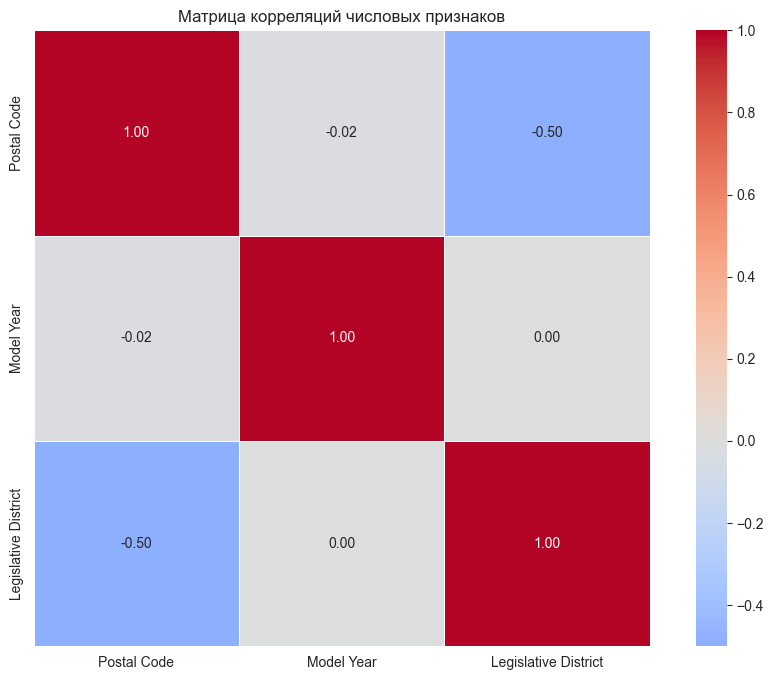

In [161]:
# Корреляция данных с помощью матрицы корреляций
#Только числовые
numeric_data = data_clean.select_dtypes(include=['int64', 'float64'])
corr_matrix = numeric_data.corr()

print(corr_matrix)

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix,
    annot=True, # Показывать или не показывать числа в ячейках
    fmt='.2f', # Формат чисел
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5
)
plt.title('Матрица корреляций числовых признаков')
plt.show()

Подготовка данных к обучению

In [162]:
#Лабораторная работа номер 1

#Подготовка данных для модели

y = data_clean['Electric Vehicle Type'] #наша целеая переменная, которую будем предсказывать.

x = data_clean.drop(columns=['Electric Vehicle Type']) #все остальное

print("Форма x: ", x.shape)
print("Форма y: ", y.shape)
print("\nКолонки x: ", x.columns.tolist())
print("\nРаспределение y:\n", y.value_counts())

Форма x:  (31175, 5)
Форма y:  (31175,)

Колонки x:  ['County', 'Postal Code', 'Model Year', 'Make', 'Legislative District']

Распределение y:
 Electric Vehicle Type
Battery Electric Vehicle (BEV)            17925
Plug-in Hybrid Electric Vehicle (PHEV)    13250
Name: count, dtype: int64


In [163]:
#кодируем категориальные признаки
x = pd.get_dummies(x, drop_first=True)

print("Форма x после one-hot: ", x.shape)
print("\nКолонки x:")
print(x.columns.tolist())

Форма x после one-hot:  (31175, 74)

Колонки x:
['Postal Code', 'Model Year', 'Legislative District', 'County_Asotin', 'County_Benton', 'County_Chelan', 'County_Clallam', 'County_Clark', 'County_Columbia', 'County_Cowlitz', 'County_Douglas', 'County_Ferry', 'County_Franklin', 'County_Garfield', 'County_Grant', 'County_Grays Harbor', 'County_Island', 'County_Jefferson', 'County_King', 'County_Kitsap', 'County_Kittitas', 'County_Klickitat', 'County_Lewis', 'County_Lincoln', 'County_Mason', 'County_Okanogan', 'County_Pacific', 'County_Pend Oreille', 'County_Pierce', 'County_San Juan', 'County_Skagit', 'County_Skamania', 'County_Snohomish', 'County_Spokane', 'County_Stevens', 'County_Thurston', 'County_Wahkiakum', 'County_Walla Walla', 'County_Whatcom', 'County_Whitman', 'County_Yakima', 'Make_AZURE DYNAMICS', 'Make_BENTLEY', 'Make_BMW', 'Make_CADILLAC', 'Make_CHEVROLET', 'Make_CHRYSLER', 'Make_FIAT', 'Make_FISKER', 'Make_FORD', 'Make_GENESIS', 'Make_HONDA', 'Make_HYUNDAI', 'Make_JAGUAR', 

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

#кодируем целевую как цифры
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Классы: ", le.classes_)

x_train, x_test, y_train, y_test = train_test_split(
    x, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("\nTrain:", x_train.shape)
print("Test:", x_test.shape)

Классы:  ['Battery Electric Vehicle (BEV)' 'Plug-in Hybrid Electric Vehicle (PHEV)']

Train: (24940, 74)
Test: (6235, 74)


In [ ]:
from sklearn.preprocessing import StandardScaler

#Числовые колонки (те, что реально числа, а не one-hot бинарные)
numeric_cols = ['Postal Code', 'Model Year', 'Legislative District']

print("Числовые колонки для нормализации:", numeric_cols)

scaler = StandardScaler()
#нормализуем значения колонок в трейн и тест    
x_train[numeric_cols] = scaler.fit_transform(x_train[numeric_cols])

x_test[numeric_cols] = scaler.transform(x_test[numeric_cols])

print("\nНормализация выполнена:")
print("Train — mean ~0, std ~1:")
print(x_train[numeric_cols].describe().loc[['mean', 'std']])
print("\nTest — mean/std из train:")
print(x_test[numeric_cols].describe().loc[['mean', 'std']])

Числовые колонки для нормализации: ['Postal Code', 'Model Year', 'Legislative District']

Нормализация выполнена:
Train — mean ~0, std ~1:
       Postal Code    Model Year  Legislative District
mean  6.262121e-16 -2.090432e-14         -7.179502e-17
std   1.000020e+00  1.000020e+00          1.000020e+00

Test — mean/std из train:
      Postal Code  Model Year  Legislative District
mean    -0.010416   -0.001989              0.030062
std      0.994081    1.007177              0.993930


Обучение моделей с подбором лучших параметров

In [ ]:
#Random Forest (случайный лес)
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

#подбор параметров для Random Forest
param_grid_rf = {
    'n_estimators': [50, 100, 200], #число деревьев
    'max_depth': [10, 15, 20, None], #максимальная глубина дерева
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid_rf,
    cv=3,
    scoring='f1_weighted',
    n_jobs=-1
)
grid_rf.fit(x_train, y_train)

print("Лучшие параметры RF:", grid_rf.best_params_)
print("Лучший F1 (CV):", grid_rf.best_score_)

#оценка лучшей модели
best_rf = grid_rf.best_estimator_
y_pred_best_rf = best_rf.predict(x_test)
y_proba_best_rf = best_rf.predict_proba(x_test)[:, 1]

print()
print("Accuracy:", accuracy_score(y_test, y_pred_best_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_best_rf))

Лучшие параметры RF: {'max_depth': 20, 'n_estimators': 100}
Лучший F1 (CV): 0.8779626742662859

Accuracy: 0.8734562951082598
ROC-AUC: 0.9479254230151838


In [ ]:
#KNN (k случайных соседей)
from sklearn.neighbors import KNeighborsClassifier

param_grid_knn = {'n_neighbors': range(3, 21, 2)}

grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    param_grid_knn,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)
grid_knn.fit(x_train, y_train)

print("Лучшие параметры KNN:", grid_knn.best_params_)
print("Лучший F1 (CV):", grid_knn.best_score_)

best_knn = grid_knn.best_estimator_
y_pred_best_knn = best_knn.predict(x_test)
y_proba_best_knn = best_knn.predict_proba(x_test)[:, 1]

print()
print("Accuracy:", accuracy_score(y_test, y_pred_best_knn))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_best_knn))

Лучшие параметры KNN: {'n_neighbors': 11}
Лучший F1 (CV): 0.8538927644283978

Accuracy: 0.8497193263833199
ROC-AUC: 0.9379352648614512


In [ ]:
#SVM (машина опорных векторов)
from sklearn.svm import SVC

param_grid_svm = {'C': [0.1, 1.0, 10.0]} #Контролирует компромисс между шириной зазора и ошибками

grid_svm = GridSearchCV(
    SVC(kernel='linear', probability=True, random_state=42),
    param_grid_svm,
    cv=3,
    scoring='f1_weighted',
    n_jobs=-1
)
grid_svm.fit(x_train, y_train)

print("Лучшие параметры SVM:", grid_svm.best_params_)
print("Лучший F1 (CV):", grid_svm.best_score_)

best_svm = grid_svm.best_estimator_
y_pred_best_svm = best_svm.predict(x_test)
y_proba_best_svm = best_svm.predict_proba(x_test)[:, 1]

print()
print("Accuracy:", accuracy_score(y_test, y_pred_best_svm))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_best_svm))

c:\Users\sasho\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Лучшие параметры SVM: {'C': 0.1}
Лучший F1 (CV): 0.8627967644423783

Accuracy: 0.8583801122694467
ROC-AUC: 0.9250068682403094


Оценка моделей

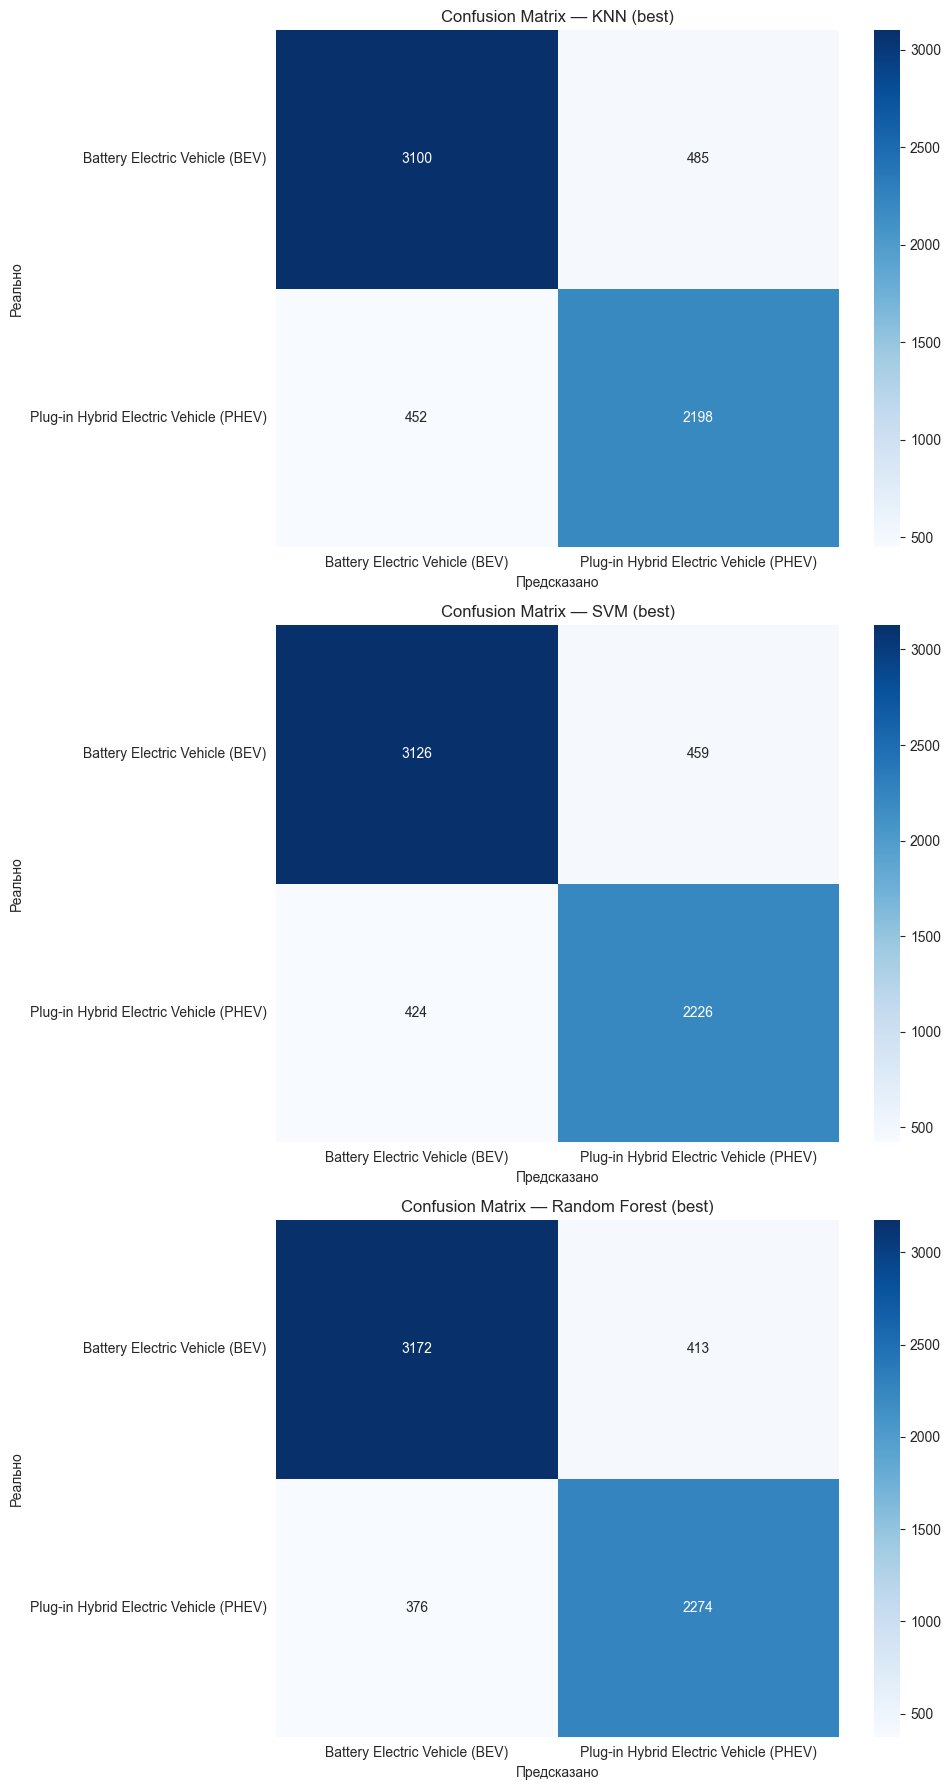

In [ ]:
#Оценка моделей
#Матрица ошибок для лучших моделей
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(3, 1, figsize=(10, 18))

for ax, (name, y_pred) in zip(axes, [
    ('KNN (best)', y_pred_best_knn),
    ('SVM (best)', y_pred_best_svm),
    ('Random Forest (best)', y_pred_best_rf)
]):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=ax,
        xticklabels=le.classes_,
        yticklabels=le.classes_
    )
    ax.set_title(f'Confusion Matrix — {name}')
    ax.set_xlabel('Предсказано')
    ax.set_ylabel('Реально')

plt.tight_layout()
plt.show()

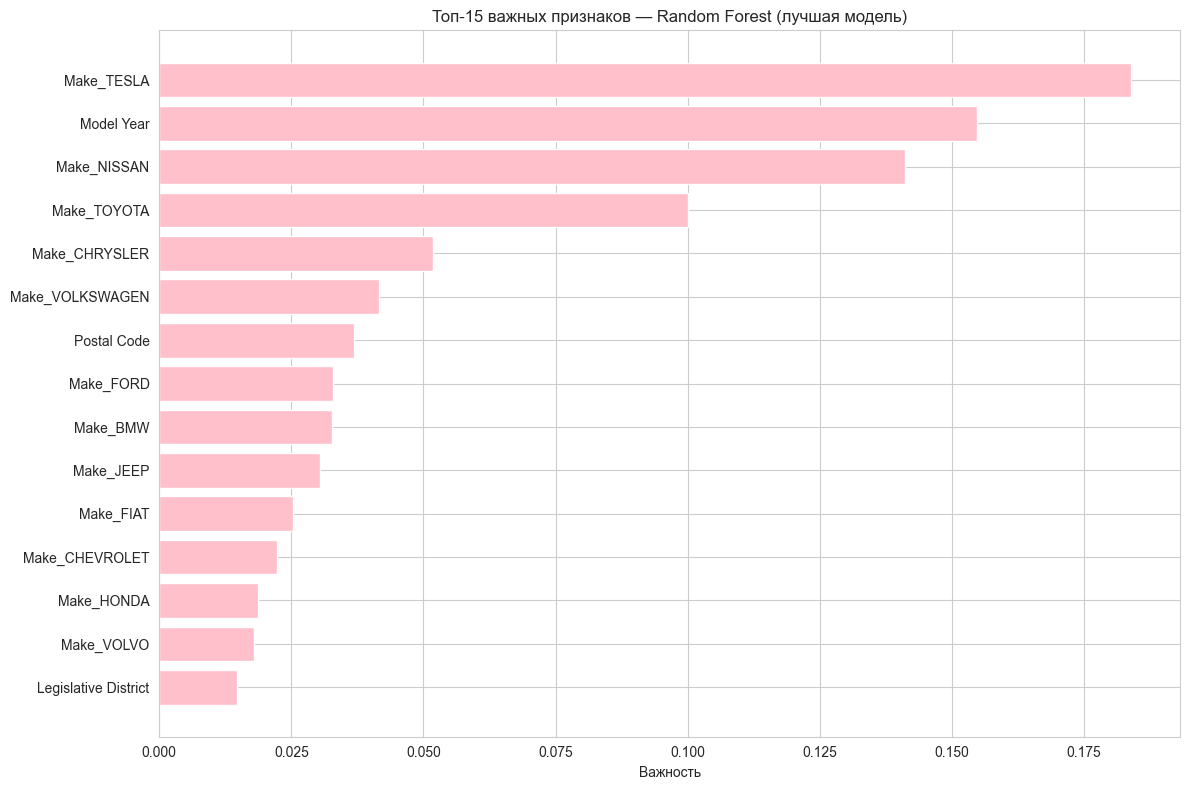

Топ-10 важных признаков (лучшая модель):
Make_TESLA: 0.1839
Model Year: 0.1547
Make_NISSAN: 0.1411
Make_TOYOTA: 0.1000
Make_CHRYSLER: 0.0517
Make_VOLKSWAGEN: 0.0415
Postal Code: 0.0369
Make_FORD: 0.0329
Make_BMW: 0.0327
Make_JEEP: 0.0305


In [173]:
#важность признаков из Random Forest (лучшая модель)
importances_best = best_rf.feature_importances_

#сортируем по убыванию
indices_best = np.argsort(importances_best)[::-1][:15]

plt.figure(figsize=(12, 8))
plt.barh(range(len(indices_best)), importances_best[indices_best], color='pink')
plt.yticks(range(len(indices_best)), [x.columns[i] for i in indices_best])
plt.xlabel('Важность')
plt.title('Топ-15 важных признаков — Random Forest (лучшая модель)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("Топ-10 важных признаков (лучшая модель):")
for i in indices_best[:10]:
    print(f"{x.columns[i]}: {importances_best[i]:.4f}")